# Patient segmentation and PCA

Which patients have similar stays, charges and health histories? This analysis uses 14 variables from 10,000 hospital records. Seven continuous measures are standardized. Seven yes/no responses are encoded as 0 or 1. The three-cluster K-Means model uses those 14 inputs. PCA projects the fitted groups into two dimensions for display.

## Load and prepare segmentation features


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

data_path = Path("data/medical_clean.csv")
if not data_path.is_file():
    data_path = Path("../data/medical_clean.csv")
df = pd.read_csv(data_path)
print(f"{len(df):,} patient records")

10,000 patient records


In [3]:
selected_columns = [
    'Age','Income','VitD_levels','Doc_visits','Initial_days',
    'TotalCharge','Additional_charges','HighBlood','Stroke',
    'Overweight','Arthritis','Diabetes','Anxiety','Soft_drink'
]

df_selected = df[selected_columns].copy()

In [4]:
df_selected.isnull().sum()

Age                   0
Income                0
VitD_levels           0
Doc_visits            0
Initial_days          0
TotalCharge           0
Additional_charges    0
HighBlood             0
Stroke                0
Overweight            0
Arthritis             0
Diabetes              0
Anxiety               0
Soft_drink            0
dtype: int64

In [5]:
binary_cols = ["HighBlood", "Stroke", "Overweight", "Arthritis", "Diabetes", "Anxiety", "Soft_drink"]
for col in binary_cols:
    df_selected[col] = df_selected[col].str.strip().str.lower().map({"yes": 1, "no": 0})
assert df_selected.notna().all().all(), "Missing or unexpected patient feature value"

## Standardize continuous measures


In [6]:
from sklearn.preprocessing import StandardScaler

continuous_cols = [
    'Age','Income','VitD_levels','Doc_visits','Initial_days','TotalCharge','Additional_charges'
]

scaler = StandardScaler()
df_selected[continuous_cols] = scaler.fit_transform(df_selected[continuous_cols])

In [7]:
cleaned_df = df_selected.copy()

## Inspect cluster count and fit K-Means


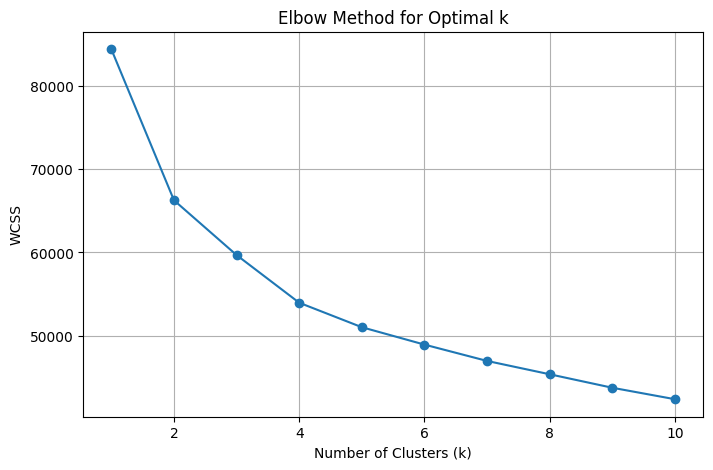

In [8]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(cleaned_df)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(range(1, 11), wcss, marker='o')
plt.title("Elbow Method for Optimal k")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("WCSS")
plt.grid(True)
plt.show()



In [9]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(cleaned_df)

cleaned_df['Cluster'] = clusters


## Display the groups with PCA


In [10]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca_results = pca.fit_transform(cleaned_df.drop('Cluster', axis=1))

cleaned_df['PCA1'] = pca_results[:, 0]
cleaned_df['PCA2'] = pca_results[:, 1]


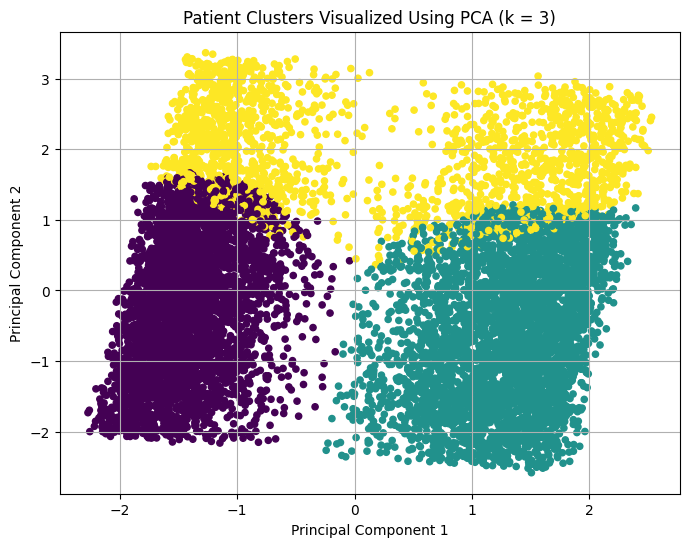

In [11]:
plt.figure(figsize=(8,6))
plt.scatter(cleaned_df['PCA1'], cleaned_df['PCA2'], 
            c=cleaned_df['Cluster'], cmap='viridis', s=20)

plt.title("Patient Clusters Visualized Using PCA (k = 3)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True)
plt.show()


In [12]:
# Simple PCA loadings display
features = [c for c in cleaned_df.columns if c not in ('Cluster', 'PCA1', 'PCA2')]
features = features[: pca.components_.shape[1]]

loadings = pd.DataFrame(
    pca.components_,
    columns=features,
    index=[f"PC{i+1}" for i in range(pca.n_components_)]
)

print(loadings.round(3))


       Age  Income  VitD_levels  Doc_visits  Initial_days  TotalCharge  \
PC1  0.096  -0.021       -0.001      -0.007         0.699        0.701   
PC2  0.675  -0.017        0.019       0.016        -0.105       -0.093   

     Additional_charges  HighBlood  Stroke  Overweight  Arthritis  Diabetes  \
PC1               0.100      0.021   0.000      -0.004      0.010     0.002   
PC2               0.708      0.152   0.009       0.002      0.001     0.001   

     Anxiety  Soft_drink  
PC1    0.008       0.001  
PC2    0.003      -0.001  


## Profiles in the original units

The table describes the fitted groups. Readmission was excluded from the inputs, so the groups alone do not establish differences in future readmission risk. Cluster numbers are arbitrary.

In [13]:
profiles = df[["Age", "Initial_days", "TotalCharge", "Additional_charges"]].copy()
profiles["HighBlood_pct"] = df_selected["HighBlood"] * 100
profiles["Cluster"] = clusters
summary = profiles.groupby("Cluster").mean()
summary.insert(0, "Patients", profiles.groupby("Cluster").size())
summary.round(1)

,Patients,Age,Initial_days,TotalCharge,Additional_charges,HighBlood_pct
Cluster,,,,,,
0,4078,48.4,9.0,3212.1,10347.5,28.6
1,4068,49.1,60.1,7400.8,10467.3,28.6
2,1854,74.4,34.0,5348.5,24038.6,95.0
